# Week 7 - Feature Changes and Temporal Robustness

In [1]:
import zipfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import confusion_matrix
from sklearn.calibration import CalibrationDisplay


zip_path = Path("csv.zip")
model_folder = Path(".")

files = {}
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        if name.lower().endswith(".csv"):
            files[Path(name).name] = name

In [2]:
# Load the files saved after full-data training
preprocessor = joblib.load(model_folder / "final_preprocessor.joblib")
threshold = joblib.load(model_folder / "final_threshold.joblib")
lr_model = joblib.load(model_folder / "final_logistic_regression.joblib")
rf_model = joblib.load(model_folder / "final_random_forest.joblib")
xgb_model = joblib.load(model_folder / "final_xgboost.joblib")

# Keep the models together so the same test steps can be applied to each one
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("All five saved files loaded successfully.")
print("Saved threshold:", threshold)
print("Encoded columns:", len(preprocessor.get_feature_names_out()))

All five saved files loaded successfully.
Saved threshold: 0.2
Encoded columns: 89


In [4]:
# Use the same predictors and target definition
numeric_features = [
    "bmi_00",
    "mental_health_days_00",
    "physical_health_days_00"
]

categorical_features = [
    "age_00", "sex_00", "race_00", "marital_status_00", "education_00",
    "income", "gen_health_00", "exercise_00", "smoked_100_cigarettes_00",
    "drinks_alcohol_00", "had_stroke_00", "had_heart_attack_00",
    "had_coronary_heart_disease_00", "cost_barrier_00",
    "l_checkup_00", "has_personal_doctor_00"
]

predictor_columns = numeric_features + categorical_features

target_map = {
    "Diabetic": 1,
    "Non-diabetic": 0,
    "Pre-diabetic": 0
}

# Check the column order before transforming test data
assert list(preprocessor.feature_names_in_) == predictor_columns
print("Predictor order matches the saved preprocessor.")

Predictor order matches the saved preprocessor.


In [6]:
def load_year(year):
    # Choose the income column for this year
    if year <= 2020:
        income_column = "income_00"
        income_maximum = 8
    else:
        income_column = "income_01"
        income_maximum = 11

    source_columns = numeric_features + categorical_features
    source_columns.remove("income")
    source_columns.append(income_column)
    source_columns.append("diabetes")

    annual_name = "DATASET_" + str(year) + ".csv"
    with zipfile.ZipFile(zip_path) as z:
        with z.open(files[annual_name]) as f:
            raw = pd.read_csv(f, usecols=source_columns, low_memory=False)

    # Keep all records with one of the expected target labels
    original_count = len(raw)
    missing_target_count = int(raw["diabetes"].isna().sum())
    mapped_target = raw["diabetes"].map(target_map)
    unexpected_target = raw["diabetes"].notna() & mapped_target.isna()
    if unexpected_target.any():
        unexpected_labels = raw.loc[unexpected_target, "diabetes"].unique()
        raise ValueError("Unexpected diabetes labels: " + str(unexpected_labels))

    clean = raw.loc[mapped_target.notna()].copy()
    clean["target"] = mapped_target.loc[mapped_target.notna()].astype("int8")
    del raw, mapped_target

    # Match income groups across years
    income = pd.to_numeric(clean[income_column], errors="coerce")
    valid_income = income.isin(range(1, income_maximum + 1))
    income = income.where(valid_income)
    clean["income"] = income.replace({9: 8, 10: 8, 11: 8})

    # Keep records with invalid predictors, but set those values to missing
    bmi = pd.to_numeric(clean["bmi_00"], errors="coerce")
    invalid_bmi = bmi.notna() & ~bmi.between(12.00, 99.99)
    clean["bmi_00"] = bmi.where(bmi.between(12.00, 99.99))
    for feature in ["mental_health_days_00", "physical_health_days_00"]:
        values = pd.to_numeric(clean[feature], errors="coerce")
        clean[feature] = values.where(values.between(0, 30))

    clean = clean[predictor_columns + ["target"]].copy()
    for feature in categorical_features:
        labels = clean[feature].astype("string")
        labels = labels.str.replace(r"\.0$", "", regex=True)
        labels = labels.fillna("<missing>")
        clean[feature] = labels.astype(str)
    for feature in numeric_features:
        clean[feature] = clean[feature].astype("float32")

    audit = {
        "year": year,
        "original_rows": original_count,
        "missing_target_rows": missing_target_count,
        "used_rows": len(clean),
        "positive_rows": int(clean["target"].sum()),
        "bmi_changed_to_missing": int(invalid_bmi.sum())
    }
    return clean, audit

In [8]:
annual_rows = []
feature_rows = []
group_data = []

for year in range(2021, 2025):
    data, audit = load_year(year)
    X = preprocessor.transform(data[predictor_columns]).astype("float32")
    y = data["target"]
    group = data[["age_00", "sex_00", "race_00", "target"]].copy()
    group["year"] = year

    for name, model in models.items():
        scores = model.predict_proba(X)[:, 1]
        predicted = scores >= threshold
        precision_curve, recall_curve, _ = precision_recall_curve(y, scores)
        annual_rows.append({
            "year": year, "model": name, "records": len(y),
            "precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0),
            "f1": f1_score(y, predicted, zero_division=0),
            "roc_auc": roc_auc_score(y, scores),
            "pr_auc": auc(recall_curve, precision_curve)
        })
        group[name] = predicted

    group_data.append(group)
    feature_rows.append({
        "year": year, "records": len(y),
        "diabetes_pct": 100 * y.mean(),
        "median_bmi": data["bmi_00"].median(),
        "bmi_missing_pct": 100 * data["bmi_00"].isna().mean(),
        "multiple_providers_pct": 100 * data["has_personal_doctor_00"].eq("More than one").mean(),
        "race_missing_pct": 100 * data["race_00"].eq("<missing>").mean(),
        "other_race_count": int(data["race_00"].eq("Other").sum())
    })
    del data, X, y

annual = pd.DataFrame(annual_rows)
features = pd.DataFrame(feature_rows)
groups = pd.concat(group_data, ignore_index=True)

## Compare features and check unusual years
I compare BMI, reports of more than one personal provider, the race field, and the share of diabetic records. Percentages use all test records for that year. BMI is summarized after the range check and before imputation.

,year,records,diabetes_pct,median_bmi,bmi_missing_pct,multiple_providers_pct,race_missing_pct,other_race_count
0,2021,437250,13.18,27.430000,10.06,28.35,2.45,3920
1,2022,442670,13.81,27.430000,10.23,30.74,3.11,0
2,2023,431746,13.84,27.400000,8.82,32.72,2.17,3338
3,2024,454774,14.46,27.440001,8.64,33.82,1.96,3720


year,2021,2022,2023,2024
race_00,,,,
<missing>,10709,13775,9377,8910
American Indian or Alaskan Native,1982,2402,2088,2063
Asian,7246,6927,6775,6427
Black,32695,35333,32757,35021
Hispanic,38268,42729,43141,48402
Multiracial,9213,9545,10091,10460
Native Hawaiian or other Pacific Islander,11369,13267,12036,12579
Other,3920,0,3338,3720
White,321848,318692,312143,327192


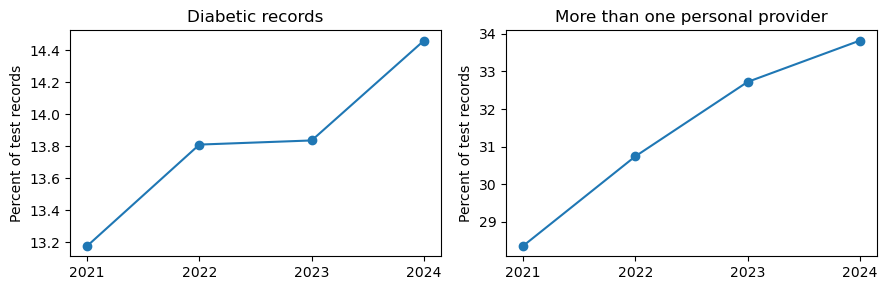

In [9]:
display(features.round(2))

race_counts = pd.crosstab(groups["race_00"], groups["year"])
display(race_counts)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, col, title in zip(
    axes, ["diabetes_pct", "multiple_providers_pct"],
    ["Diabetic records", "More than one personal provider"]
):
    ax.plot(features["year"], features[col], marker="o")
    ax.set_title(title)
    ax.set_ylabel("Percent of test records")
    ax.set_xticks([2021, 2022, 2023, 2024])
plt.tight_layout()
plt.show()

The share of diabetic records increased from 13.18% to 14.46%, and the share reporting more than one personal provider rose from 28.35% to 33.82%. 

Median BMI changed from 27.43 to 27.44. 

In the 2022 file, the race label “Other” had zero records and the missing race share was 3.11%, the highest of the four years. This is a difference in the processed file. I cannot tell from these tables why the label was absent or whether it affected model scores.

## Compare performance by demographic group
I keep the original age codes and combine nearby codes into three bands. I use the sex and race labels in the processed files. Missing group labels are excluded from that group comparison but kept in the yearly results.

Each table uses the same threshold of 0.20. I show group counts and diabetes percentages because these help explain why precision and recall can differ. Groups with fewer than 100 diabetic or 100 non-diabetic records in a year have their scores left blank.

In [10]:
# Group neighboring age codes without changing the model inputs
age = pd.to_numeric(groups["age_00"], errors="coerce")
groups["age_band"] = pd.cut(
    age, bins=[0, 4, 9, 13], labels=["Codes 1–4", "Codes 5–9", "Codes 10–13"]
)

subgroup_rows = []
for variable in ["age_band", "sex_00", "race_00"]:
    known = groups[groups[variable].notna() & groups[variable].ne("<missing>")]
    for (year, label), rows in known.groupby(["year", variable], observed=True):
        y = rows["target"]
        positives = int(y.sum())
        enough = positives >= 100 and len(y) - positives >= 100
        for name in models:
            predicted = rows[name]
            subgroup_rows.append({
                "year": year, "variable": variable, "group": label, "model": name,
                "records": len(y), "diabetic": positives,
                "diabetes_pct": 100 * y.mean(),
                "precision": precision_score(y, predicted, zero_division=0) if enough else np.nan,
                "recall": recall_score(y, predicted, zero_division=0) if enough else np.nan,
                "f1": f1_score(y, predicted, zero_division=0) if enough else np.nan
            })

subgroups = pd.DataFrame(subgroup_rows)

# Show a compact F1 table for all three models and all four test years
short_names = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB"}
subgroups["short_model"] = subgroups["model"].map(short_names)
comparison = subgroups.pivot(
    index=["variable", "group"], columns=["year", "short_model"], values="f1"
)
display(comparison.round(4))

# Show the latest year's counts and all three threshold-based metrics
latest = subgroups[subgroups["year"].eq(2024)]
with pd.option_context("display.max_rows", None):
    display(latest.drop(columns=["short_model"]).round(4))

year                                                  2021                  \
short_model                                             LR      RF     XGB   
variable group                                                               
age_band Codes 10–13                                0.4641  0.4524  0.4671   
         Codes 1–4                                  0.1615  0.2012  0.1800   
         Codes 5–9                                  0.4275  0.4189  0.4301   
race_00  American Indian or Alaskan Native          0.4909  0.4747  0.4925   
         Asian                                      0.4946  0.4831  0.4977   
         Black                                      0.5015  0.4804  0.5006   
         Hispanic                                   0.4844  0.4680  0.4861   
         Multiracial                                0.4506  0.4273  0.4443   
         Native Hawaiian or other Pacific Islander  0.4175  0.3600  0.3932   
         Other                                      0.4465  0.4209  0.4394   
         White                                      0.4241  0.4135  0.4290   
sex_00   Female                                     0.4340  0.4212  0.4369   
         Male                                       0.4492  0.4343  0.4515   

year                                                  2022                  \
short_model                                             LR      RF     XGB   
variable group                                                               
age_band Codes 10–13                                0.4738  0.4619  0.4748   
         Codes 1–4                                  0.1553  0.2030  0.1757   
         Codes 5–9                                  0.4313  0.4192  0.4335   
race_00  American Indian or Alaskan Native          0.5156  0.5000  0.5013   
         Asian                                      0.5054  0.4900  0.5122   
         Black                                      0.5050  0.4872  0.5037   
         Hispanic                                   0.4948  0.4756  0.4935   
         Multiracial                                0.4634  0.4468  0.4629   
         Native Hawaiian or other Pacific Islander  0.4123  0.3669  0.3994   
         Other                                         NaN     NaN     NaN   
         White                                      0.4300  0.4164  0.4323   
sex_00   Female                                     0.4411  0.4278  0.4416   
         Male                                       0.4576  0.4388  0.4586   

year                                                  2023                  \
short_model                                             LR      RF     XGB   
variable group                                                               
age_band Codes 10–13                                0.4644  0.4527  0.4667   
         Codes 1–4                                  0.1493  0.1939  0.1647   
         Codes 5–9                                  0.4334  0.4218  0.4347   
race_00  American Indian or Alaskan Native          0.5290  0.5120  0.5403   
         Asian                                      0.5185  0.4969  0.5146   
         Black                                      0.5000  0.4892  0.5032   
         Hispanic                                   0.4817  0.4654  0.4817   
         Multiracial                                0.4523  0.4388  0.4588   
         Native Hawaiian or other Pacific Islander  0.4250  0.3818  0.4250   
         Other                                      0.4261  0.4093  0.4270   
         White                                      0.4261  0.4114  0.4287   
sex_00   Female                                     0.4368  0.4222  0.4386   
         Male                                       0.4524  0.4360  0.4539   

year                                                  2024                  
short_model                                             LR      RF     XGB  
variable group                                                              
age_band Codes 10–13  

,year,variable,group,model,records,diabetic,diabetes_pct,precision,recall,f1
27,2024,age_band,Codes 1–4,Logistic Regression,107970,2860,2.6489,0.2404,0.1241,0.1637
28,2024,age_band,Codes 1–4,Random Forest,107970,2860,2.6489,0.1628,0.2843,0.2070
29,2024,age_band,Codes 1–4,XGBoost,107970,2860,2.6489,0.2423,0.1437,0.1804
30,2024,age_band,Codes 5–9,Logistic Regression,168898,24573,14.5490,0.3612,0.5593,0.4390
31,2024,age_band,Codes 5–9,Random Forest,168898,24573,14.5490,0.3517,0.5520,0.4296
32,2024,age_band,Codes 5–9,XGBoost,168898,24573,14.5490,0.3469,0.6010,0.4399
33,2024,age_band,Codes 10–13,Logistic Regression,169888,37346,21.9827,0.3586,0.6803,0.4697
34,2024,age_band,Codes 10–13,Random Forest,169888,37346,21.9827,0.3773,0.5813,0.4576
35,2024,age_band,Codes 10–13,XGBoost,169888,37346,21.9827,0.3651,0.6643,0.4713
54,2024,sex_00,Female,Logistic Regression,238670,32932,13.7981,0.3508,0.5773,0.4364


In 2024, XGBoost recall was 0.144 for age codes 1–4 and 0.664 for codes 10–13. 

Recall was 0.601 for Female records and 0.632 for Male records. The race table also shows differences across groups. A blank for “Other” in 2022 means there were no records with that label. Group size and diabetes rates differ, so I use these as descriptive comparisons.